### 1. Import libraries

In [1]:
import cv2
import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("NumPy:", np.__version__)
print("\nAll libraries imported successfully!")

OpenCV: 4.11.0
MediaPipe: 0.10.21
NumPy: 1.26.4

All libraries imported successfully!


### 2. Load one video from GRID

In [2]:
# Locate the project folder
project_root = Path.cwd().parent

# Locate the GRID videos
video_folder = (
    project_root
    / "data"
    / "datasets"
    / "GRID"
    / "speaker_01"
    / "raw_videos"
)

# Find all MPG videos
video_files = sorted(video_folder.rglob("*.mpg"))
print("Number of videos:", len(video_files))

# Select the first video
video_path = video_files[0]
print("\nSelected video:")
print(video_path)

Number of videos: 1000

Selected video:
c:\Users\linah\OneDrive\Documenti\GitHub\intelligent_lip_detection\data\datasets\GRID\speaker_01\raw_videos\s1\bbaf2n.mpg


### 3. Extract one frame from the video

Frame extracted successfully!
Frame shape: (288, 360, 3)


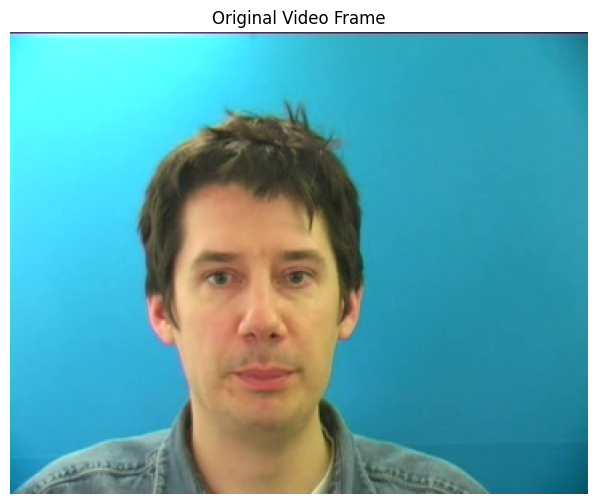

In [3]:
cap = cv2.VideoCapture(str(video_path)) # Open the selected video

frame_number = 30
cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number) # Select frame number 30

success, frame = cap.read() # Read the frame

cap.release() # Release the video
if success:
    frame_rgb = cv2.cvtColor(frame,cv2.COLOR_BGR2RGB) # Convert BGR to RGB
    print("Frame extracted successfully!")
    print("Frame shape:", frame_rgb.shape)
    plt.figure(figsize=(10, 6))
    plt.imshow(frame_rgb)
    plt.title("Original Video Frame")
    plt.axis("off")
    plt.show()
else:
    print("Could not extract the frame.")

### 4. Initialize MediaPipe Face Mesh

In [4]:
# Initialize MediaPipe Face Mesh
mp_face_mesh = mp.solutions.face_mesh
face_mesh = mp_face_mesh.FaceMesh(
    static_image_mode=True,
    max_num_faces=1,
    refine_landmarks=True,
    min_detection_confidence=0.5
)
print("MediaPipe Face Mesh initialized successfully!")

MediaPipe Face Mesh initialized successfully!


### 5. Detect the face

In [5]:
results = face_mesh.process(frame_rgb) # Process the RGB frame
if results.multi_face_landmarks:   # Check whether a face was detected
    print("Face detected successfully!")
    print("Number of detected faces:",len(results.multi_face_landmarks))
    face_landmarks = results.multi_face_landmarks[0]
    print("Number of facial landmarks:",len(face_landmarks.landmark))
else:
    print("No face detected in this frame.")

Face detected successfully!
Number of detected faces: 1
Number of facial landmarks: 478


### 6. Draw the facial landmarks

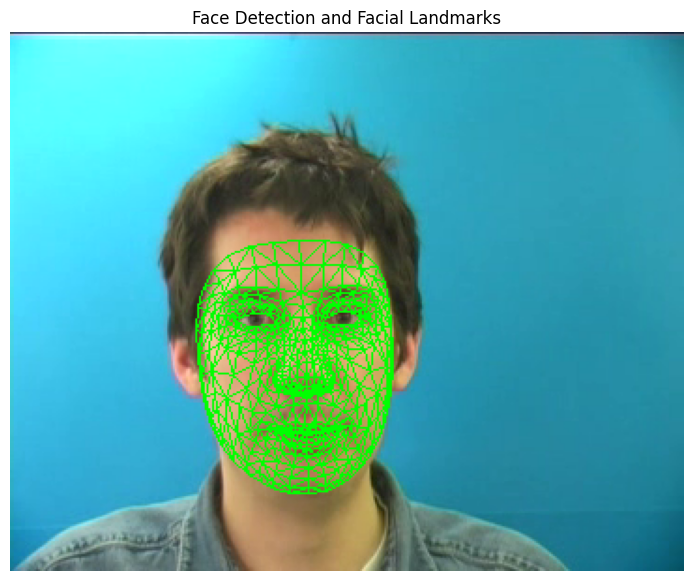

In [6]:
annotated_frame = frame_rgb.copy()  # Make a copy of the original frame
if results.multi_face_landmarks:
    # Draw all facial landmarks
    mp.solutions.drawing_utils.draw_landmarks(
        image=annotated_frame,
        landmark_list=face_landmarks,
        connections=mp_face_mesh.FACEMESH_TESSELATION,
        landmark_drawing_spec=None,
        connection_drawing_spec=(
            mp.solutions.drawing_utils.DrawingSpec(
                color=(0, 255, 0),
                thickness=1,
                circle_radius=1
            )
        )
    )
    # Display the result
    plt.figure(figsize=(10, 7))
    plt.imshow(annotated_frame)
    plt.title("Face Detection and Facial Landmarks")
    plt.axis("off")
    plt.show()

### 7. Detect and draw only the lips

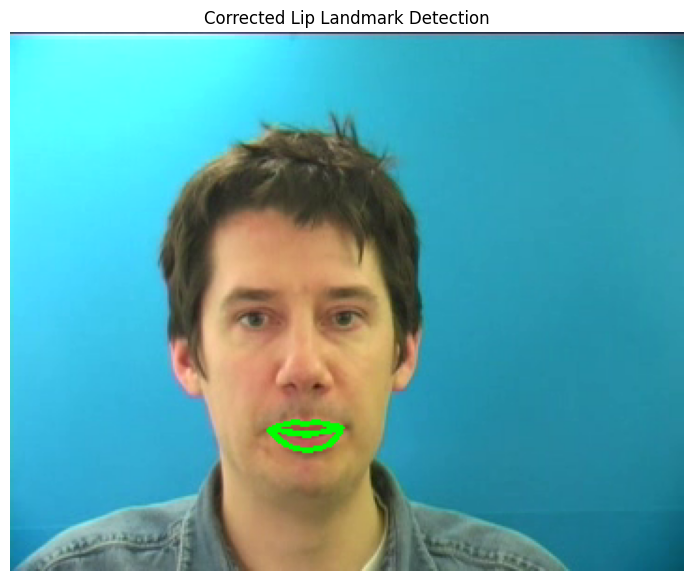

In [9]:
lip_frame = frame_rgb.copy()   # Create a copy of the original frame
if results.multi_face_landmarks:
    # Draw only the lip connections
    mp.solutions.drawing_utils.draw_landmarks(
        image=lip_frame,
        landmark_list=face_landmarks,

        # Connections around the lips
        connections=mp_face_mesh.FACEMESH_LIPS,

        # Do not draw all facial landmarks
        landmark_drawing_spec=None,

        # Draw only the lip connections
        connection_drawing_spec=(
            mp.solutions.drawing_utils.DrawingSpec(
                color=(0, 255, 0),
                thickness=2,
                circle_radius=2
            )
        )
    )

    plt.figure(figsize=(10, 7))
    plt.imshow(lip_frame)
    plt.title("Corrected Lip Landmark Detection")
    plt.axis("off")
    plt.show()
else:
    print("No face detected.")

### 8. Extract the mouth region

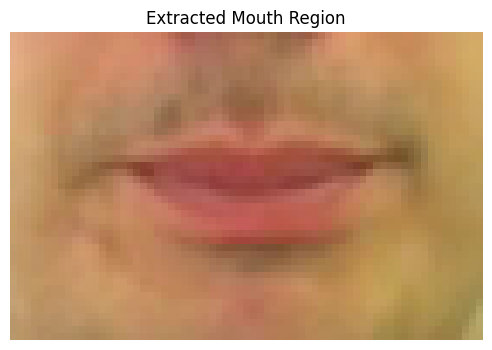

Mouth region extracted successfully!
Mouth crop shape: (45, 69, 3)


In [10]:
if results.multi_face_landmarks:
    # Get all landmark indices connected to the lips
    lip_indices = set()
    for connection in mp_face_mesh.FACEMESH_LIPS:
        lip_indices.update(connection)

    # Convert normalized coordinates to pixel coordinates
    height, width, _ = frame_rgb.shape
    lip_points = []
    for index in lip_indices:
        landmark = face_landmarks.landmark[index]
        x = int(landmark.x * width)
        y = int(landmark.y * height)
        lip_points.append((x, y))
    lip_points = np.array(lip_points)

    # Calculate the mouth boundaries
    x_min = np.min(lip_points[:, 0])
    x_max = np.max(lip_points[:, 0])
    y_min = np.min(lip_points[:, 1])
    y_max = np.max(lip_points[:, 1])

    # Add padding around the mouth
    padding = 15
    x_min = max(0, x_min - padding)
    x_max = min(width, x_max + padding)
    y_min = max(0, y_min - padding)
    y_max = min(height, y_max + padding)

    # Crop the mouth
    mouth_crop = frame_rgb[
        y_min:y_max,
        x_min:x_max
    ]
    
    # Display the mouth crop
    plt.figure(figsize=(8, 4))
    plt.imshow(mouth_crop)
    plt.title("Extracted Mouth Region")
    plt.axis("off")
    plt.show()
    print("Mouth region extracted successfully!")
    print("Mouth crop shape:", mouth_crop.shape)
else:
    print("Cannot extract the mouth because no face was detected.")